# Lab 7: Forecasting with a Coupled Oscillator Network

Student: Lopatenko George (334771)  
Course: Machine Learning for Time Series (TSML)

I compare a network of trainable damped oscillators with the MLP and LSTM architectures from Lab 4. The electricity-load, ECG and SPY series are unchanged, as are the ten forecast origins at each horizon. The question is whether oscillatory hidden dynamics help a small network retain the recurring structure of these signals.

In [1]:
import os
from pathlib import Path

for variable in ["OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"]:
    os.environ[variable] = "1"

import copy
import textwrap
import time

import numpy as np
import pandas as pd
import plotly.graph_objects as go
import torch
from IPython.display import Image, display
from plotly.subplots import make_subplots
from prettytable import PrettyTable
from torch import nn

SEED = 42
torch.set_num_threads(1)
TSML_DIR = next(path for path in [Path.cwd(), Path.cwd() / "tsml", Path.cwd().parent]
                if (path / "lab-2/data/SPY_AdjClose.csv").exists())
COLORS = {"Oscillator": "#D55E00", "ReLU MLP": "#0072B2", "Sigmoid MLP": "#777777",
          "LSTM": "#009E73", "Hawkes": "#D55E00", "Poisson": "#0072B2", "Observed": "#252525"}


def show_table(frame, title, decimals=3):
    table = PrettyTable()
    table.title = title
    table.field_names = list(frame.columns)
    table.align = "l"
    for row in frame.itertuples(index=False, name=None):
        table.add_row([f"{value:.{decimals}f}" if isinstance(value, (float, np.floating)) else value for value in row])
    print(table)


def show_figure(fig, caption, height=650, width=1000):
    has_legend = any(trace.showlegend is not False for trace in fig.data)
    top = 150 if has_legend else 105
    plot_height = height - top - 185
    for annotation in fig.layout.annotations:
        annotation.font = dict(size=20, color="#252525")
    fig.update_layout(
        template="plotly_white", width=width, height=height,
        font=dict(family="Arial", size=20, color="#252525"),
        title=dict(x=0.02, xanchor="left", y=1-18/height, yanchor="top", font=dict(size=24)),
        margin=dict(l=100, r=45, t=top, b=185),
        legend=dict(orientation="h", x=0, y=1+65/plot_height, yanchor="bottom"),
    )
    caption = "<br>".join(textwrap.wrap(caption, width=82))
    fig.add_annotation(text=caption, x=0, y=0, yshift=-100, xref="paper", yref="paper", showarrow=False,
                       xanchor="left", yanchor="top", align="left", font=dict(size=20, color="#555555"))
    fig.update_xaxes(showgrid=False, zeroline=False)
    fig.update_yaxes(gridcolor="#E5E7EB", zeroline=False)
    display(Image(data=fig.to_image(format="png", scale=2), alt=fig.layout.title.text))


## 1. Three forecasting problems

**EU hourly load.** The final 720 hourly observations cover 30 days. Demand has a daily activity cycle and a changing weekly level. A 48-hour context contains two daily cycles; forecasts of 1, 7 and 14 steps mean hours.

**Normal ECG.** Six separately segmented normal beats, each 140 samples long, form an 840-sample sequence. A full beat is the input context. The repeated P–QRS–T morphology is useful, but the artificial joins do not represent a continuous clinical recording. Forecast horizons here are samples.

**SPY close.** The final 750 daily prices retain the same observations used in Lab 4. The local source labels the price column `Close`; the earlier report called it adjusted close, but the saved column alone does not establish its adjustment convention. Forecast horizons mean trading sessions. A persistent price level can be easy to follow even when its next return is unpredictable.

Data sources are the Darts/ENTSO-E load collection, TensorFlow ECG anomaly dataset and the Yahoo Finance SPY snapshot retained in Lab 2.

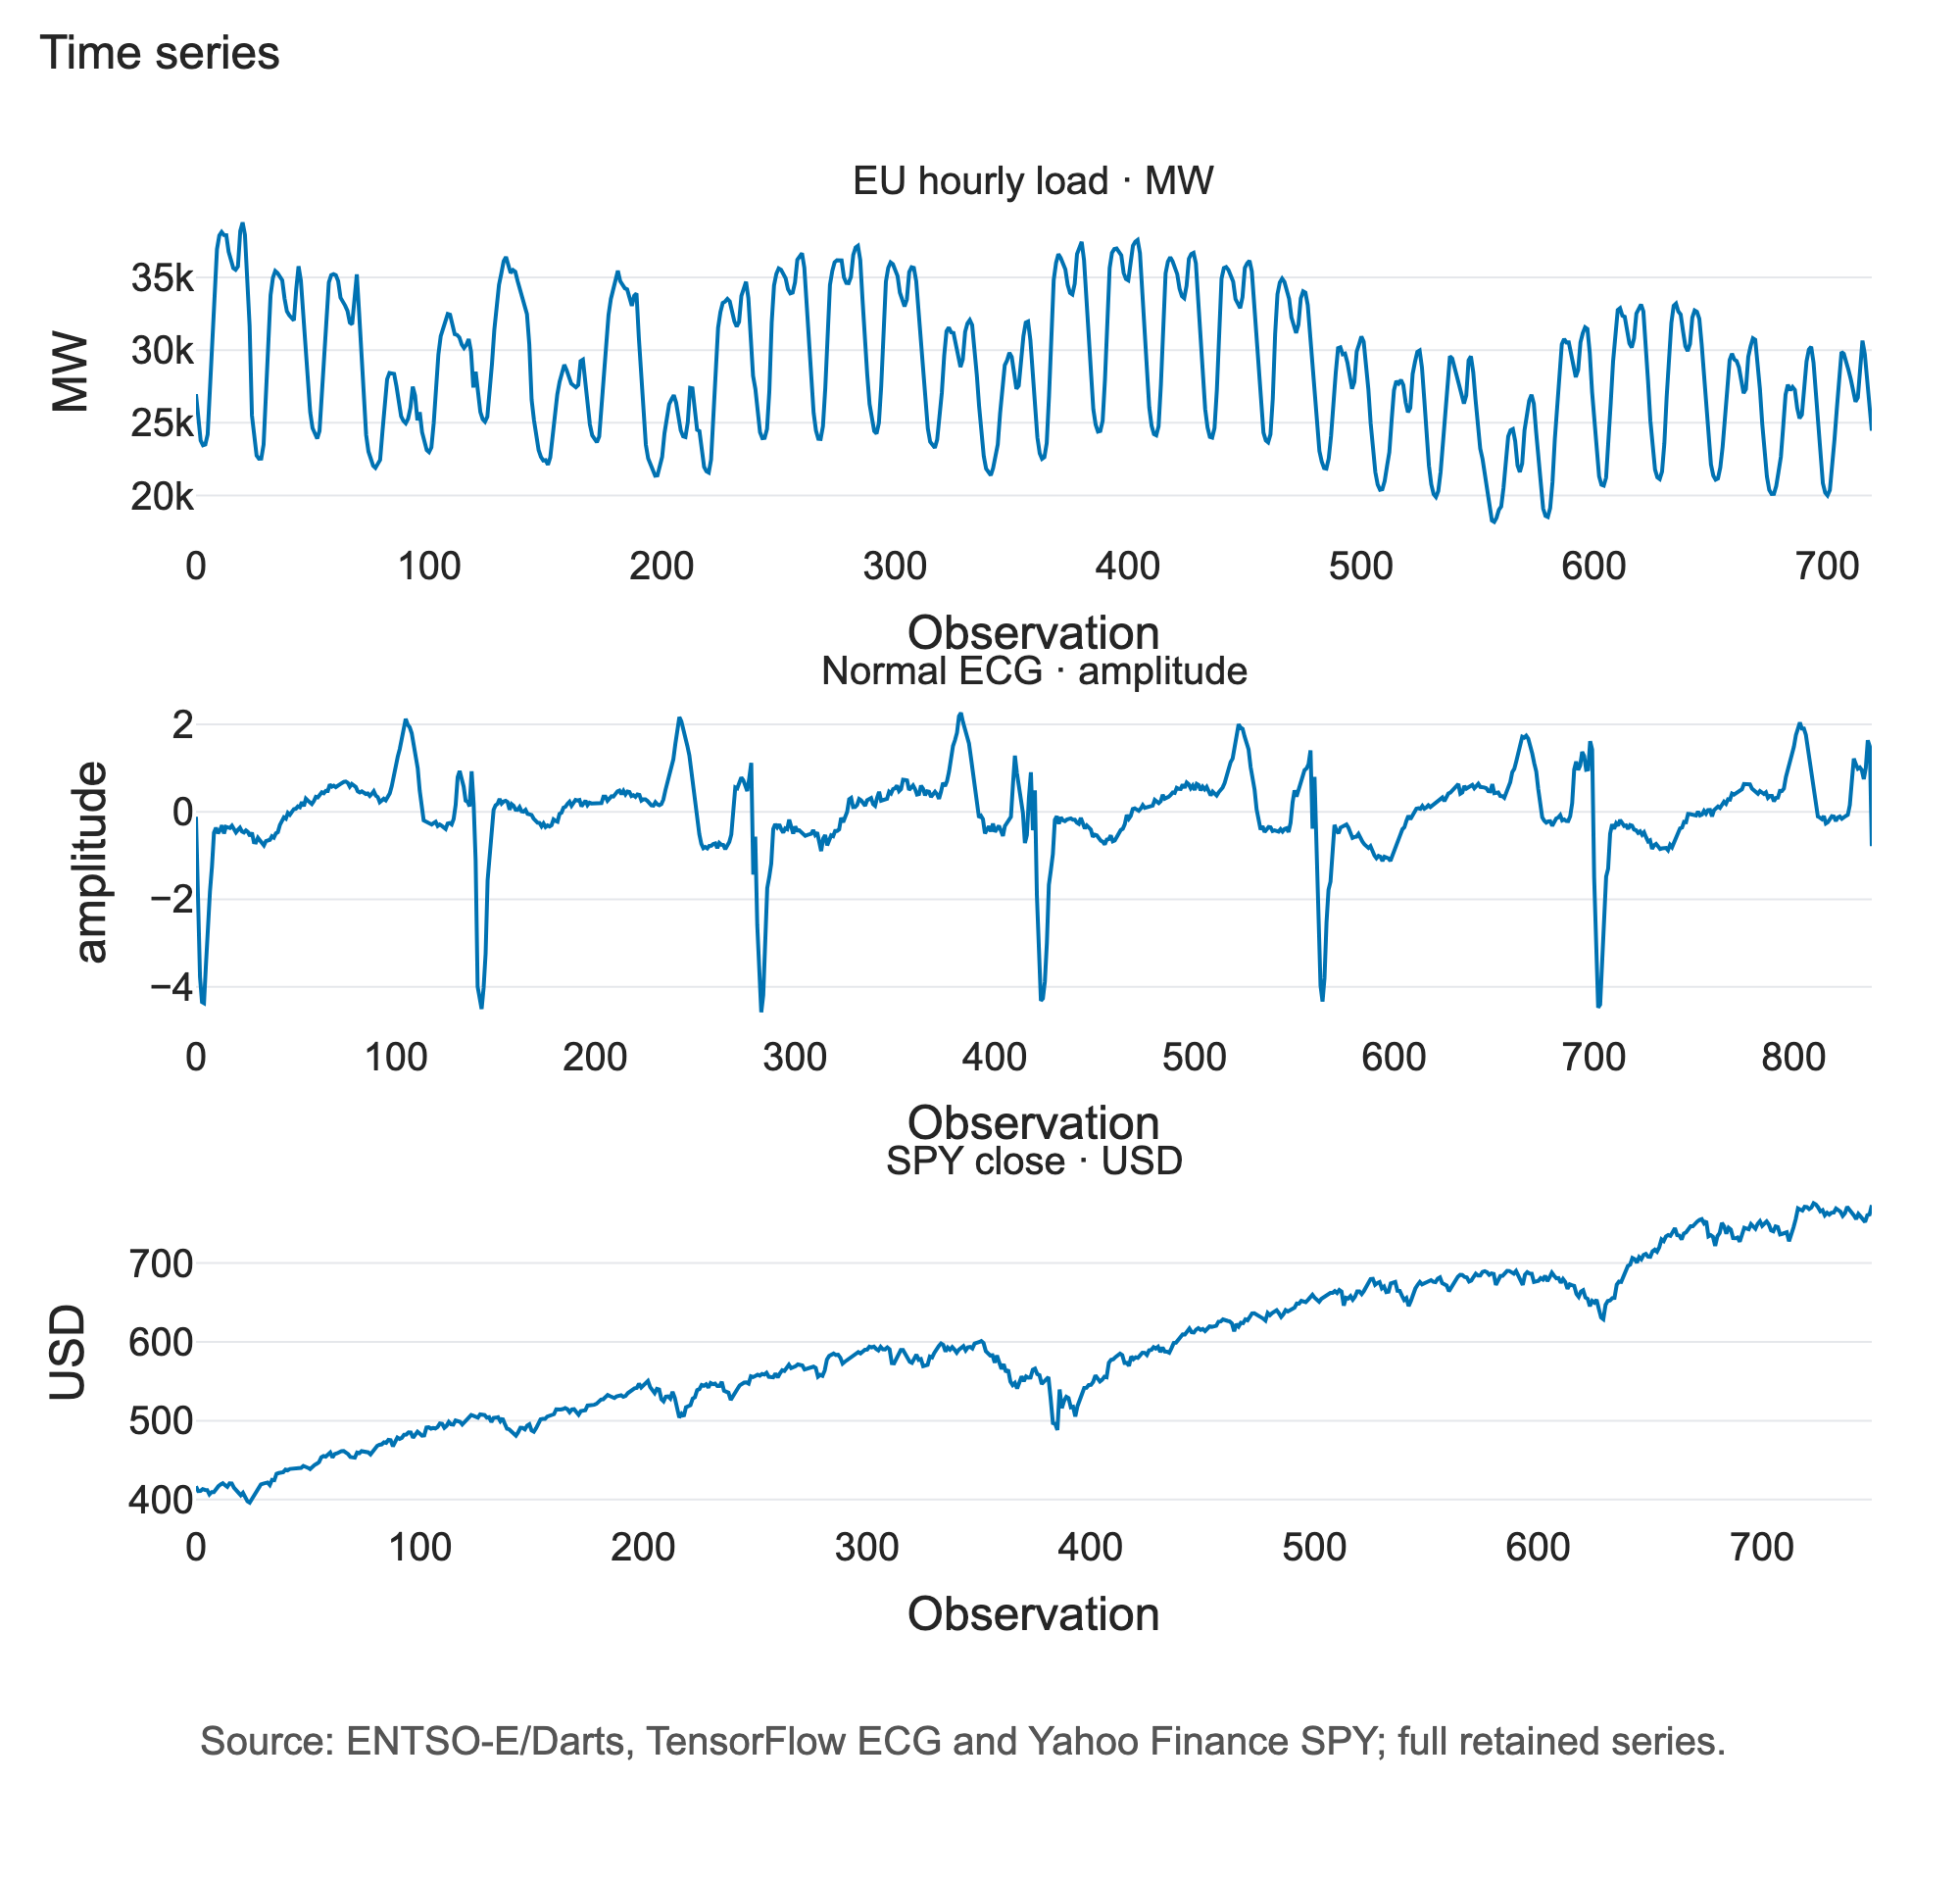

In [2]:
energy = pd.read_csv(TSML_DIR / "lab-2/data/energy_dataset.csv").dropna(subset=["total load actual"]).iloc[-720:]
ecg = pd.read_csv(TSML_DIR / "lab-2/data/ecg.csv", header=None)
beats = ecg[ecg.iloc[:, -1] == 1].iloc[:6, :-1].to_numpy(float)
prices = pd.read_csv(TSML_DIR / "lab-2/data/SPY_AdjClose.csv", parse_dates=["Date"]).dropna().sort_values("Date")
price_column = next(name for name in ["SPY", "Adj Close", "Close"] if name in prices)

arrays = {
    "EU_Hourly_Load": energy["total load actual"].to_numpy(float),
    "ECG_TF_Normal": beats.ravel(),
    "SPY_AdjClose": prices[price_column].to_numpy(float)[-750:],
}
LABELS = {"EU_Hourly_Load": "EU hourly load", "ECG_TF_Normal": "Normal ECG", "SPY_AdjClose": "SPY close"}
WINDOWS = {"EU_Hourly_Load": 48, "ECG_TF_Normal": 140, "SPY_AdjClose": 20}
UNITS = {"EU_Hourly_Load": "MW", "ECG_TF_Normal": "amplitude", "SPY_AdjClose": "USD"}
labels = {"EU_Hourly_Load": "EU hourly load · MW", "ECG_TF_Normal": "Normal ECG · amplitude", "SPY_AdjClose": "SPY close · USD"}
fig = make_subplots(rows=3, cols=1, subplot_titles=list(labels.values()), vertical_spacing=0.12)
for row, key in enumerate(labels, 1):
    fig.add_trace(go.Scatter(x=np.arange(len(arrays[key])), y=arrays[key], mode="lines", line=dict(color="#0072B2", width=2), showlegend=False), row=row, col=1)
    fig.update_xaxes(title_text="Observation", row=row, col=1)
    fig.update_yaxes(title_text=labels[key].split(" · ")[1], row=row, col=1)
fig.update_layout(title="Time series")
show_figure(fig, "Source: ENTSO-E/Darts, TensorFlow ECG and Yahoo Finance SPY; full retained series.", height=960)

The load cycles repeat with changing amplitude; the ECG has sharper, shorter structures. SPY mostly preserves its latest level. These differences matter: a model that smooths its state can track broad demand changes while losing the QRS shape, and can still produce plausible prices without predicting returns.

## 2. A network with position and velocity states

The recurrent core follows the coupled-oscillator construction of [Rusch and Mishra (2021)](https://arxiv.org/abs/2010.00951). Each hidden unit has a position $y$ and velocity $z$. The observed input drives the units, and trainable coupling lets one unit affect the others:

$$
f_t=\tanh(W_y y_t+W_z z_t+Vx_t+b),\qquad
z_{t+1}=\frac{z_t+\Delta t(f_t-\gamma y_t)}{1+\Delta t\epsilon},\qquad
y_{t+1}=y_t+\Delta t z_{t+1}.
$$

The update treats damping implicitly. The restoring term $-\gamma y_t$ pulls the state toward equilibrium, while $\epsilon$ controls friction. With 16 units, $\Delta t=0.1$ and $\gamma=\epsilon=1$, the linear readout predicts the next standardized observation from the final position. All coupling and readout weights are learned by backpropagation; the integration constants stay fixed. They describe hidden dynamics rather than a physical frequency in hours or heartbeats.

In [3]:
import copy
import time

import numpy as np
import torch
from torch import nn


class OscillatorForecaster(nn.Module):
    def __init__(self, hidden_size=16, dt=0.1, gamma=1.0, damping=1.0):
        super().__init__()
        self.hidden_size = hidden_size
        self.dt = dt
        self.gamma = gamma
        self.damping = damping
        self.force = nn.Linear(2 * hidden_size + 1, hidden_size)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        position = x.new_zeros((len(x), self.hidden_size))
        velocity = torch.zeros_like(position)
        for sample in x.unbind(dim=1):
            state = torch.cat([position, velocity, sample[:, None]], dim=1)
            force = torch.tanh(self.force(state))
            # Implicit damping and the new velocity stabilize the discrete update.
            velocity = (velocity + self.dt * (force - self.gamma * position)) / (1 + self.dt * self.damping)
            position = position + self.dt * velocity
        return self.output(position).squeeze(-1)


def supervised_windows(values, window):
    x = np.array([values[end - window:end] for end in range(window, len(values))], dtype=np.float32)
    return x, np.asarray(values[window:], dtype=np.float32)


class ThreeLayerMLP(nn.Module):
    def __init__(self, window, activation):
        super().__init__()
        nonlinearity = nn.ReLU if activation == "relu" else nn.Sigmoid
        self.network = nn.Sequential(
            nn.Linear(window, 32), nonlinearity(),
            nn.Linear(32, 16), nonlinearity(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.network(x).squeeze(-1)


class LSTMForecaster(nn.Module):
    def __init__(self, hidden_size=16):
        super().__init__()
        self.lstm = nn.LSTM(1, hidden_size, batch_first=True)
        self.output = nn.Linear(hidden_size, 1)

    def forward(self, x):
        sequence, _ = self.lstm(x.unsqueeze(-1))
        return self.output(sequence[:, -1]).squeeze(-1)


def neural_forecast(train, horizon, window, model_name, seed, max_epochs=80, patience=8):
    started = time.perf_counter()
    torch.manual_seed(seed)
    center, scale = float(np.mean(train)), max(float(np.std(train)), 1e-12)
    normalized = (np.asarray(train) - center) / scale
    x, y = supervised_windows(normalized, window)
    x, y = x[-384:], y[-384:]
    n_validation = max(1, int(np.ceil(len(x) * 0.15)))
    x_train, y_train = torch.from_numpy(x[:-n_validation]), torch.from_numpy(y[:-n_validation])
    x_valid, y_valid = torch.from_numpy(x[-n_validation:]), torch.from_numpy(y[-n_validation:])

    if model_name == "Oscillator":
        model, learning_rate = OscillatorForecaster(), 0.005
    elif model_name == "LSTM":
        model, learning_rate = LSTMForecaster(), 0.005
    else:
        model = ThreeLayerMLP(window, "relu" if model_name == "ReLU MLP" else "sigmoid")
        learning_rate = 0.010
    optimizer = torch.optim.Adam(model.parameters(), lr=learning_rate, weight_decay=1e-4)
    loss_function = nn.MSELoss()
    best_loss, stale = np.inf, 0
    best_state = copy.deepcopy(model.state_dict())
    history = []
    for epoch in range(max_epochs):
        model.train()
        optimizer.zero_grad()
        loss = loss_function(model(x_train), y_train)
        loss.backward()
        if model_name == "Oscillator":
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        model.eval()
        with torch.no_grad():
            validation_loss = float(loss_function(model(x_valid), y_valid))
        history.append({"epoch": epoch + 1, "train_mse": float(loss.detach()), "validation_mse": validation_loss})
        if validation_loss < best_loss - 1e-6:
            best_loss = validation_loss
            best_state = copy.deepcopy(model.state_dict())
            stale = 0
        else:
            stale += 1
            if stale >= patience:
                break
    model.load_state_dict(best_state)
    fit_seconds = time.perf_counter() - started

    started = time.perf_counter()
    values = normalized.tolist()
    predictions = []
    with torch.no_grad():
        for _ in range(horizon):
            context = torch.tensor(values[-window:], dtype=torch.float32)[None]
            value = float(model(context).item())
            values.append(value)
            predictions.append(center + scale * value)
    forecast_seconds = time.perf_counter() - started
    return np.asarray(predictions), fit_seconds, forecast_seconds, history

## 3. Forecast protocol

For horizon $h$, the final $10h$ observations form ten adjacent, non-overlapping test blocks. At every origin, the network is initialized again and fitted to the available historical prefix. Recursive forecasting feeds each prediction back into the next input window; it never consumes the true test values.

Each origin retains at most 384 supervised windows. The last 15% is chronological validation. Training uses MSE, Adam with weight decay $10^{-4}$, at most 80 epochs and patience 8. The oscillator and LSTM learning rate is 0.005; the MLP learning rate is 0.010. Only the oscillator clips gradient norm to 1. Its seed is matched to LSTM at every origin.

Scaling uses the entire observed prefix, including its inner validation tail, to retain the Lab 4 protocol exactly. This is test-safe but the inner validation loss is not a strictly independent preprocessing estimate. No test observations enter fitting or scaling. All four networks are fitted here on the same origins: 360 fits in total. The MLP and LSTM architectures, learning rates and seeds follow Lab 4.

MAPE is retained for comparability. Because ECG crosses zero, MAE in original amplitude units is the primary ECG interpretation; very large percentage errors can reflect a small denominator. The ten blocks are a chronological sample of forecast errors, not ten independent initialization repetitions.

In [4]:
def forecast_metrics(actual, predicted):
    absolute = np.abs(np.asarray(actual) - np.asarray(predicted))
    nonzero = np.abs(actual) > 1e-12
    return {
        "mape": float(100 * np.mean(absolute[nonzero] / np.abs(actual[nonzero]))),
        "mae": float(np.mean(absolute)),
    }


rows, paths, histories = [], [], []
models = ["ReLU MLP", "Sigmoid MLP", "LSTM", "Oscillator"]
for series_number, key in enumerate(LABELS):
    values = arrays[key]
    for horizon_number, horizon in enumerate((1, 7, 14)):
        for split in range(1, 11):
            origin = len(values) - (11 - split) * horizon
            actual = values[origin:origin + horizon]
            base_seed = SEED + series_number * 90 + horizon_number * 30 + (split - 1) * 3
            for model_number, model_name in enumerate(models):
                seed = base_seed + min(model_number + 1, 3)
                predicted, fit_seconds, forecast_seconds, history = neural_forecast(
                    values[:origin], horizon, WINDOWS[key], model_name, seed
                )
                rows.append({
                    "series": key, "model": model_name, "horizon": horizon, "split": split,
                    "origin": origin, "seed": seed, **forecast_metrics(actual, predicted),
                    "fit_seconds": fit_seconds, "forecast_seconds": forecast_seconds, "epochs": len(history),
                })
                paths.extend({
                    "series": key, "model": model_name, "horizon": horizon, "split": split,
                    "step": step, "actual": observed, "predicted": estimate,
                } for step, (observed, estimate) in enumerate(zip(actual, predicted), 1))
                if model_name == "Oscillator":
                    histories.extend({"series": key, "horizon": horizon, "split": split, **row} for row in history)

comparison = pd.DataFrame(rows)
all_paths = pd.DataFrame(paths)
training_history = pd.DataFrame(histories)
summary = comparison.groupby(["series", "model", "horizon"], as_index=False).agg(
    mean_mape=("mape", "mean"), median_mape=("mape", "median"), mean_mae=("mae", "mean")
)


## 4. Forecast errors

In [5]:
for key, label in LABELS.items():
    table = summary[summary.series == key].copy()
    table["model"] = pd.Categorical(table.model, categories=models, ordered=True)
    table = table.sort_values(["horizon", "model"])
    table = table[["horizon", "model", "mean_mape", "median_mape", "mean_mae"]].rename(columns={
        "horizon": "h", "model": "Model", "mean_mape": "Mean MAPE (%)",
        "median_mape": "Median MAPE (%)", "mean_mae": f"Mean MAE ({UNITS[key]})",
    })
    show_table(table, label)


+--------------------------------------------------------------------+
|                           EU hourly load                           |
+----+-------------+---------------+-----------------+---------------+
| h  | Model       | Mean MAPE (%) | Median MAPE (%) | Mean MAE (MW) |
+----+-------------+---------------+-----------------+---------------+
| 1  | ReLU MLP    | 4.666         | 4.999           | 1263.948      |
| 1  | Sigmoid MLP | 7.470         | 7.313           | 2055.485      |
| 1  | LSTM        | 4.811         | 3.871           | 1348.871      |
| 1  | Oscillator  | 7.524         | 7.417           | 2120.839      |
| 7  | ReLU MLP    | 4.829         | 3.892           | 1233.660      |
| 7  | Sigmoid MLP | 7.373         | 6.052           | 1850.004      |
| 7  | LSTM        | 9.260         | 7.745           | 2311.645      |
| 7  | Oscillator  | 12.081        | 7.772           | 2859.701      |
| 14 | ReLU MLP    | 5.432         | 5.511           | 1460.183      |
| 14 |

The oscillator has mean load MAPE of **7.52%**, **12.08%** and **13.72%** as the horizon increases. ReLU MLP remains stronger at every horizon. An oscillatory state alone does not guarantee that the short training sequence identifies the demand cycle well.

On ECG, the oscillator's mean MAE is **1.173**, **0.628** and **0.614**. Its lower 14-step MAPE than LSTM does not make it the best ECG model: ReLU MLP has lower MAE at all three horizons. The two metrics answer different questions near zero crossings.

For SPY, oscillator MAPE is **3.78%**, **4.63%** and **4.89%**. It improves on the LSTM under this setup but stays well behind ReLU MLP. That partial improvement is about following the local price level; it provides no evidence of profitable return prediction.

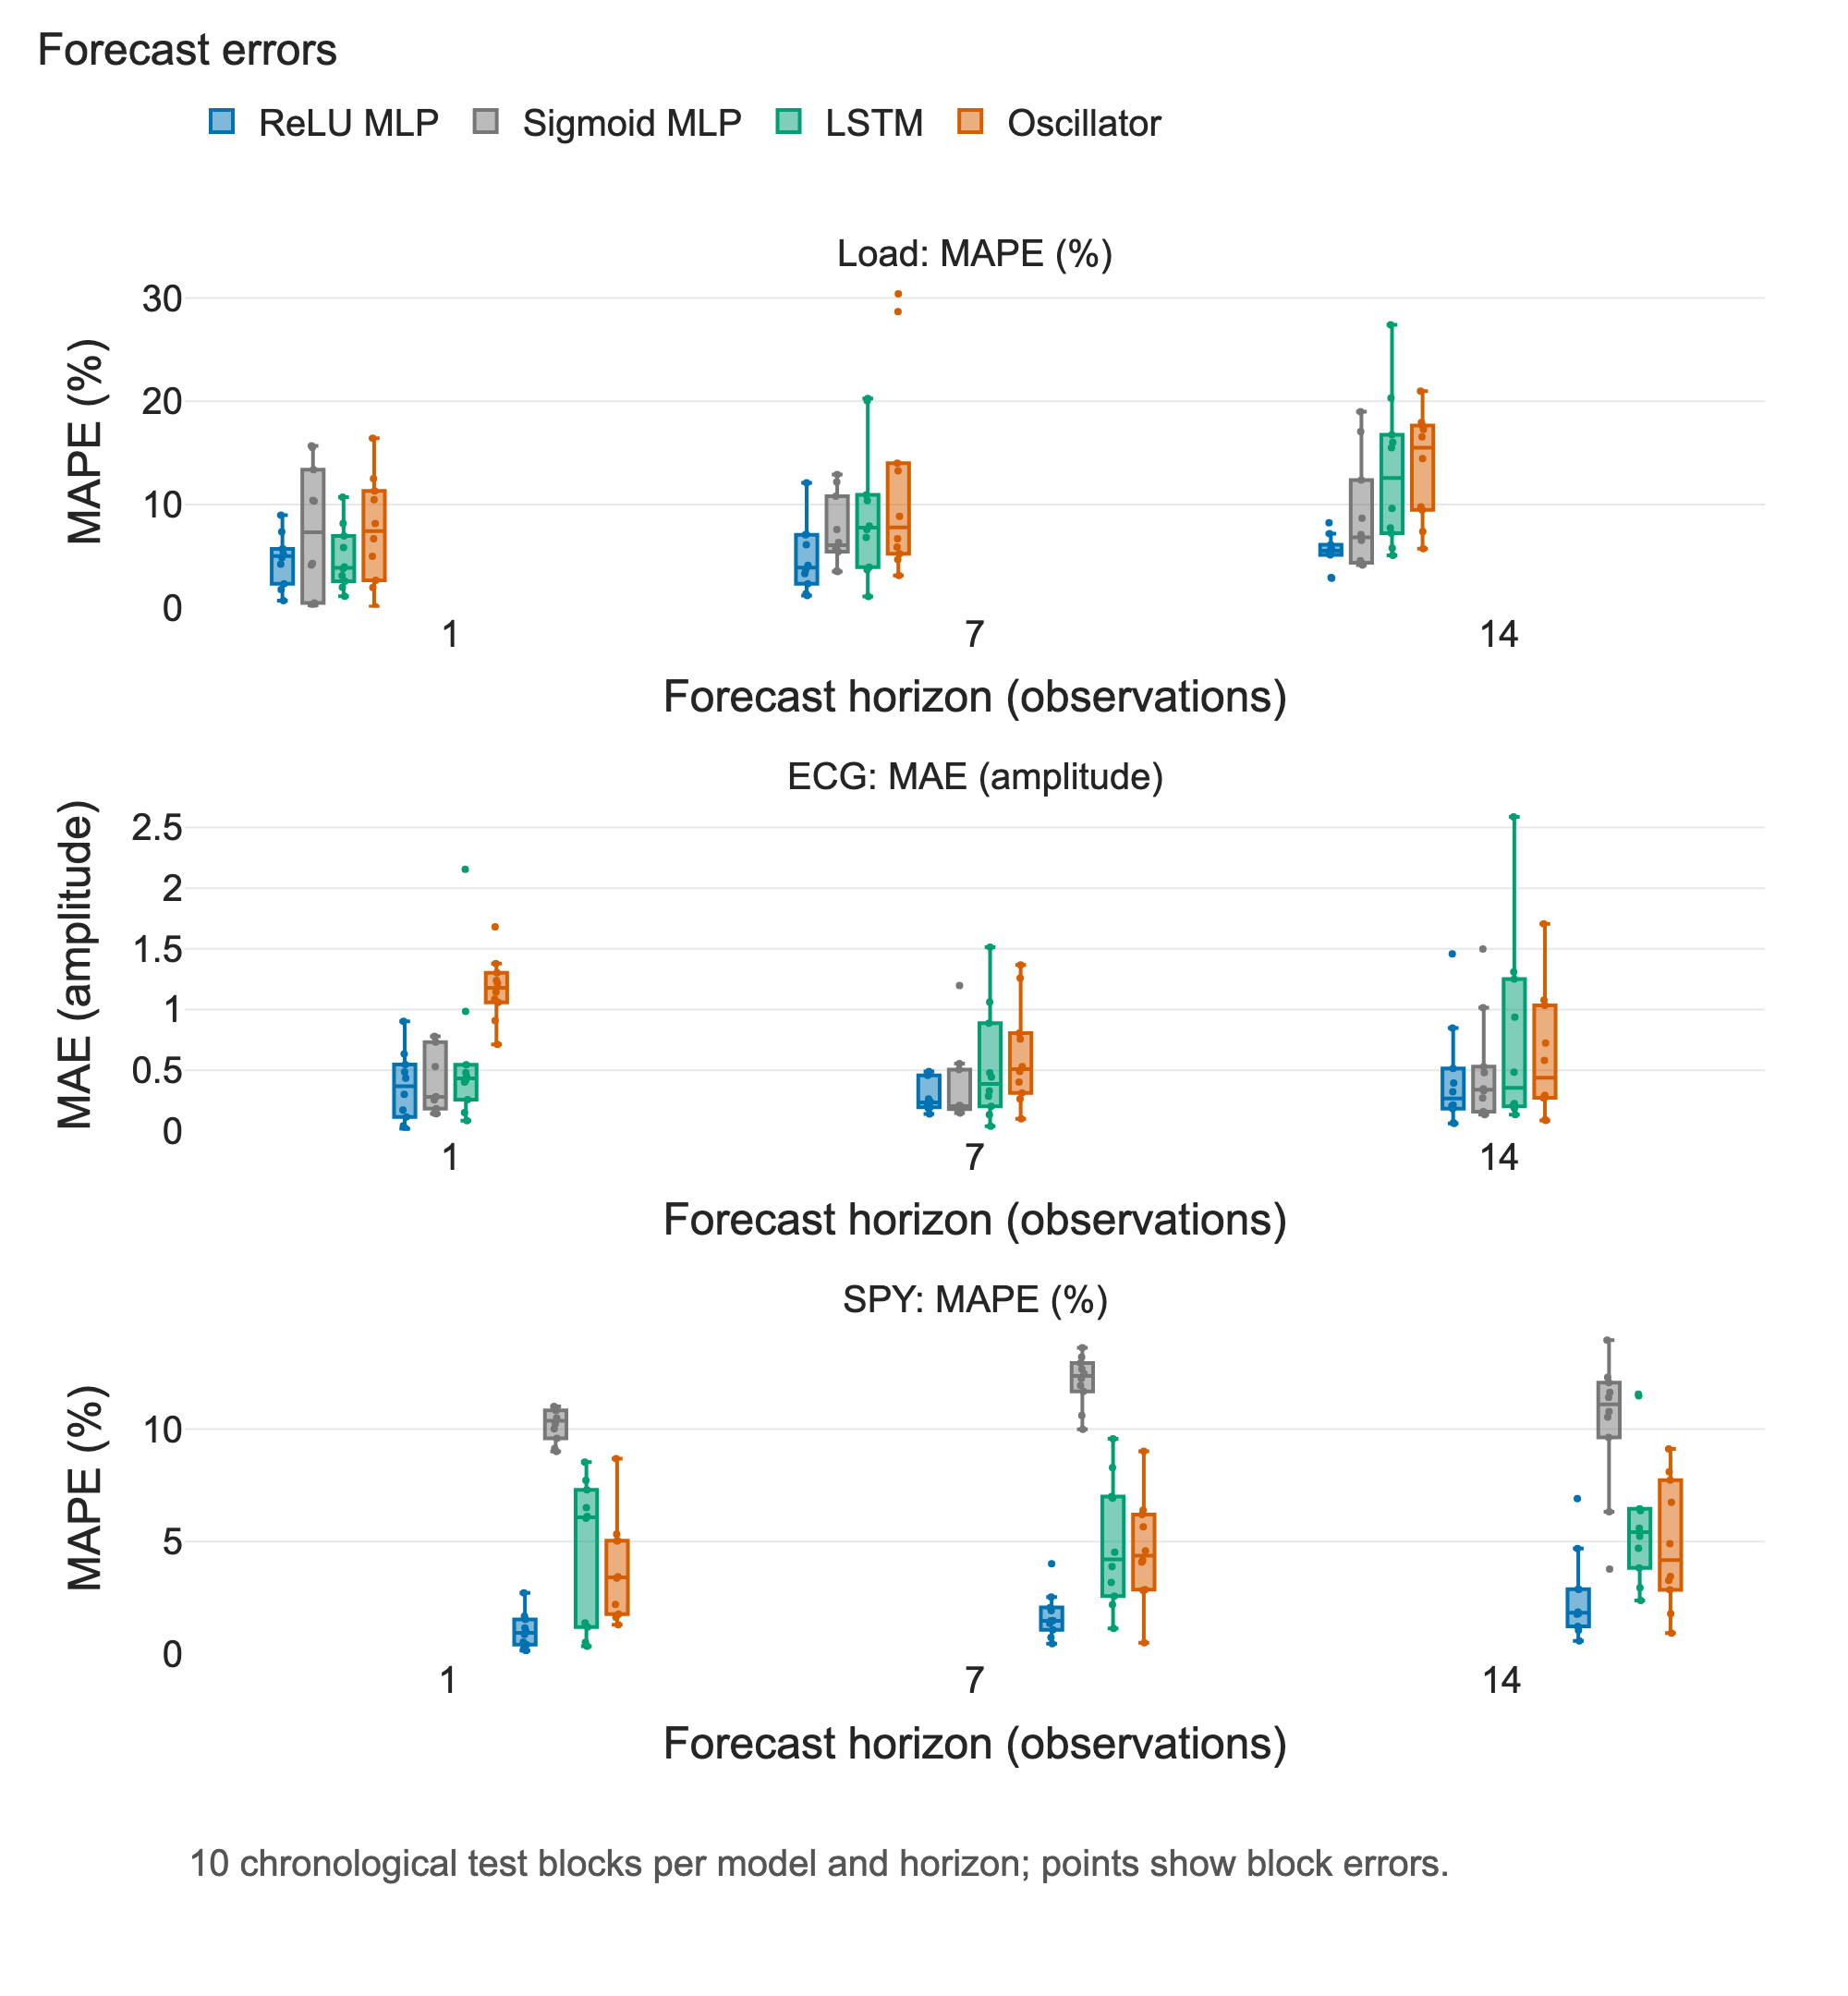

In [6]:
fig = make_subplots(rows=3, cols=1, subplot_titles=["Load: MAPE (%)", "ECG: MAE (amplitude)", "SPY: MAPE (%)"], vertical_spacing=0.14)
for row, key in enumerate(LABELS, 1):
    metric = "mae" if key == "ECG_TF_Normal" else "mape"
    for model in ["ReLU MLP", "Sigmoid MLP", "LSTM", "Oscillator"]:
        group = comparison[(comparison.series == key) & (comparison.model == model)]
        fig.add_trace(go.Box(x=group.horizon.astype(str), y=group[metric], name=model, legendgroup=model, showlegend=row == 1,
                            marker_color=COLORS[model], boxpoints="all", jitter=0.2, pointpos=0, marker_size=4), row=row, col=1)
    fig.update_xaxes(title_text="Forecast horizon (observations)", row=row, col=1)
    fig.update_yaxes(title_text="MAE (amplitude)" if metric == "mae" else "MAPE (%)", rangemode="tozero", row=row, col=1)
fig.update_layout(title="Forecast errors", boxmode="group")
show_figure(fig, "10 chronological test blocks per model and horizon; points show block errors.", height=1080)

The individual points show why a mean alone is insufficient: different test blocks have very different difficulty. ECG is plotted in MAE so that zero crossings do not dominate the comparison. The distributions overlap, but the oscillator's error is not systematically below the dense network's error.

### Matched-block differences

Positive MAE gains favour the oscillator. The same held-out block is used on both sides of each subtraction; comparisons are in MW, normalized amplitude and USD, respectively.



In [7]:
paired_rows = []
for key, label in LABELS.items():
    for horizon in (1, 7, 14):
        frame = comparison[(comparison.series == key) & (comparison.horizon == horizon)].pivot(
            index="split", columns="model", values="mae"
        )
        paired_rows.append({
            "Series": label, "h": horizon,
            "MAE gain vs ReLU": (frame["ReLU MLP"] - frame.Oscillator).mean(),
            "MAE gain vs LSTM": (frame.LSTM - frame.Oscillator).mean(),
            "Beats LSTM": f"{int((frame.Oscillator < frame.LSTM).sum())}/10",
        })
show_table(pd.DataFrame(paired_rows), "Positive MAE gains favour the oscillator")


+------------------------------------------------------------------------+
|                Positive MAE gains favour the oscillator                |
+----------------+----+------------------+------------------+------------+
| Series         | h  | MAE gain vs ReLU | MAE gain vs LSTM | Beats LSTM |
+----------------+----+------------------+------------------+------------+
| EU hourly load | 1  | -856.891         | -771.968         | 4/10       |
| EU hourly load | 7  | -1626.041        | -548.056         | 4/10       |
| EU hourly load | 14 | -1835.336        | -51.050          | 3/10       |
| Normal ECG     | 1  | -0.808           | -0.580           | 1/10       |
| Normal ECG     | 7  | -0.340           | -0.091           | 4/10       |
| Normal ECG     | 14 | -0.187           | 0.138            | 5/10       |
| SPY close      | 1  | -20.921          | 6.053            | 5/10       |
| SPY close      | 7  | -22.046          | 2.438            | 4/10       |
| SPY close      | 14 | -

## 5. Forecast shape and training dynamics

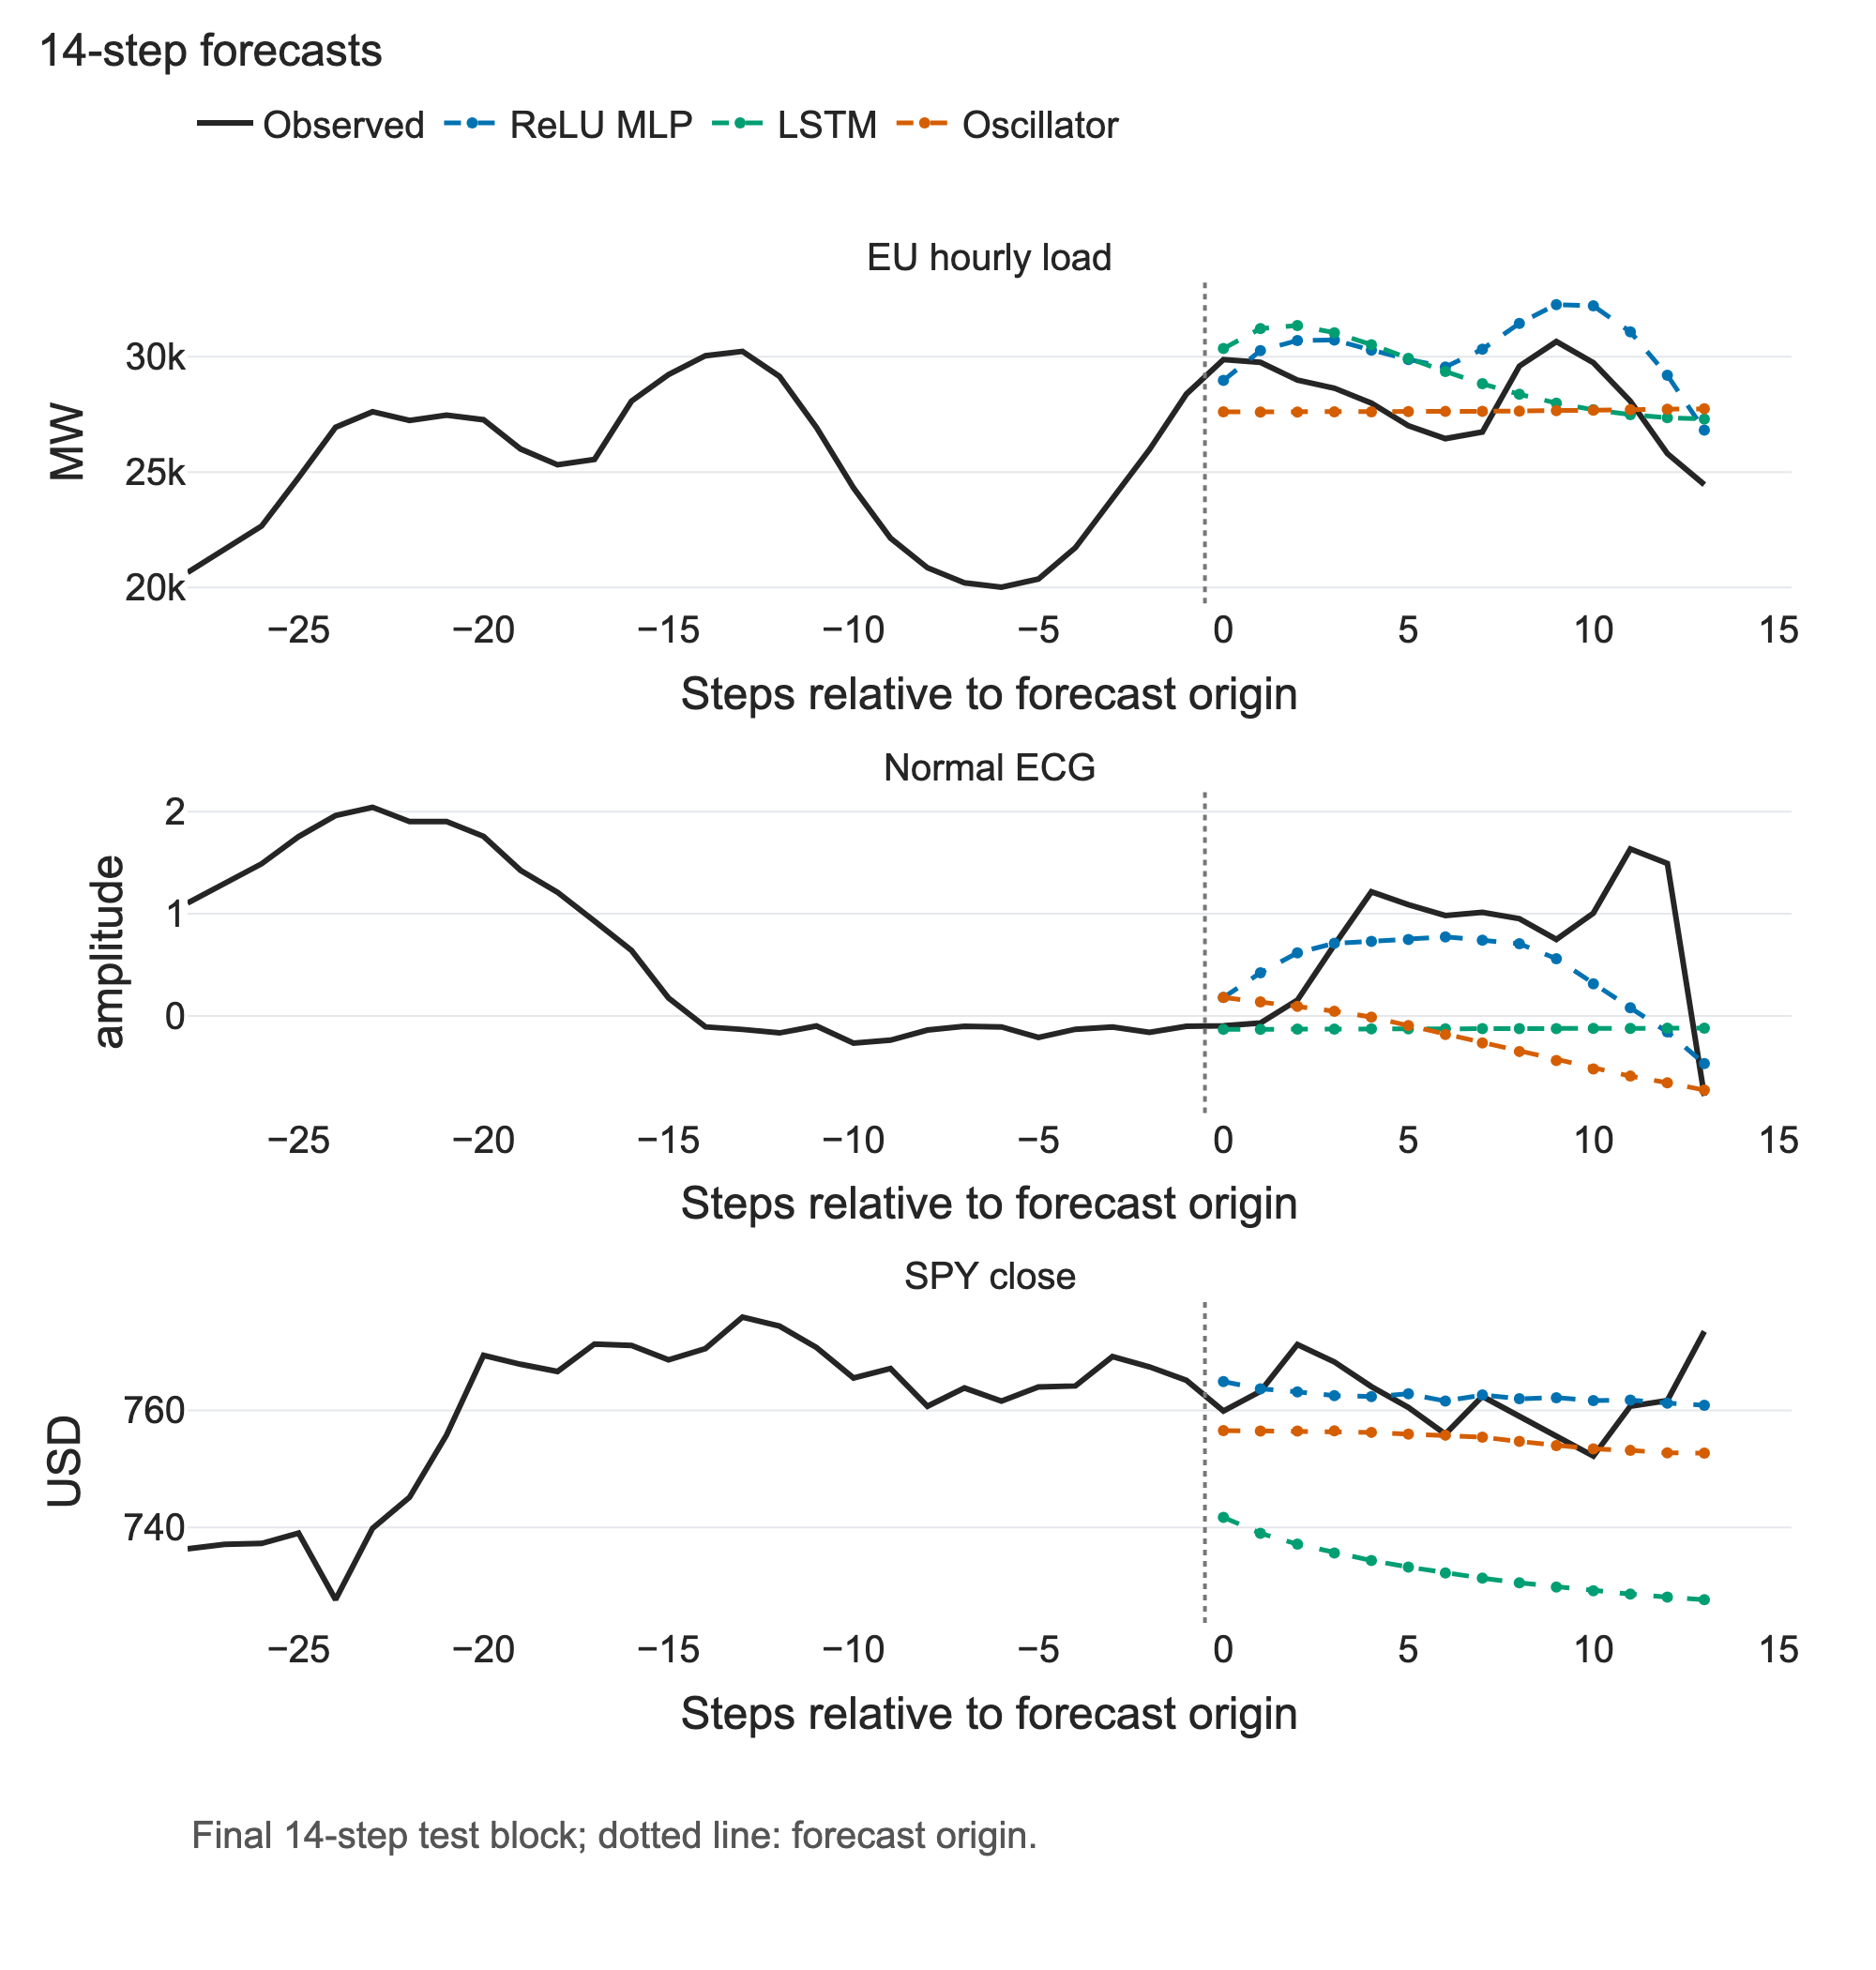

In [8]:
fig = make_subplots(rows=3, cols=1, subplot_titles=list(LABELS.values()), vertical_spacing=0.14)
for row, key in enumerate(LABELS, 1):
    origin = len(arrays[key]) - 14
    context = 28
    fig.add_trace(go.Scatter(x=np.arange(-context, 14), y=arrays[key][origin-context:origin+14], name="Observed", legendgroup="Observed", showlegend=row == 1,
                            line=dict(color="#252525", width=3)), row=row, col=1)
    group = all_paths[(all_paths.series == key) & (all_paths.horizon == 14) & (all_paths.split == 10)]
    for model in ["ReLU MLP", "LSTM", "Oscillator"]:
        values = group[group.model == model].sort_values("step").predicted
        fig.add_trace(go.Scatter(x=np.arange(14), y=values, name=model, legendgroup=model, showlegend=row == 1,
                                line=dict(color=COLORS[model], width=2.5, dash="dash")), row=row, col=1)
    fig.add_vline(x=-0.5, line_dash="dot", line_color="#777777", row=row, col=1)
    fig.update_xaxes(title_text="Steps relative to forecast origin", row=row, col=1)
    fig.update_yaxes(title_text=UNITS[key], row=row, col=1)
fig.update_layout(title="14-step forecasts")
show_figure(fig, "Final 14-step test block; dotted line: forecast origin.", height=1050)

These are the final blocks fixed by the evaluation design, rather than examples selected for a favourable result. The load oscillator is almost flat and misses the decline after the second peak. In ECG it moves downward while the observed waveform rises; on SPY it stays below the recent level, although it is less biased than this LSTM path. These are distinct failure modes, not simply larger random scatter around the correct forecast.

Once a forecast deviates, feeding it back changes the following hidden states and can make later errors larger. The black path is the observed test sequence, not an input available during recursive forecasting.

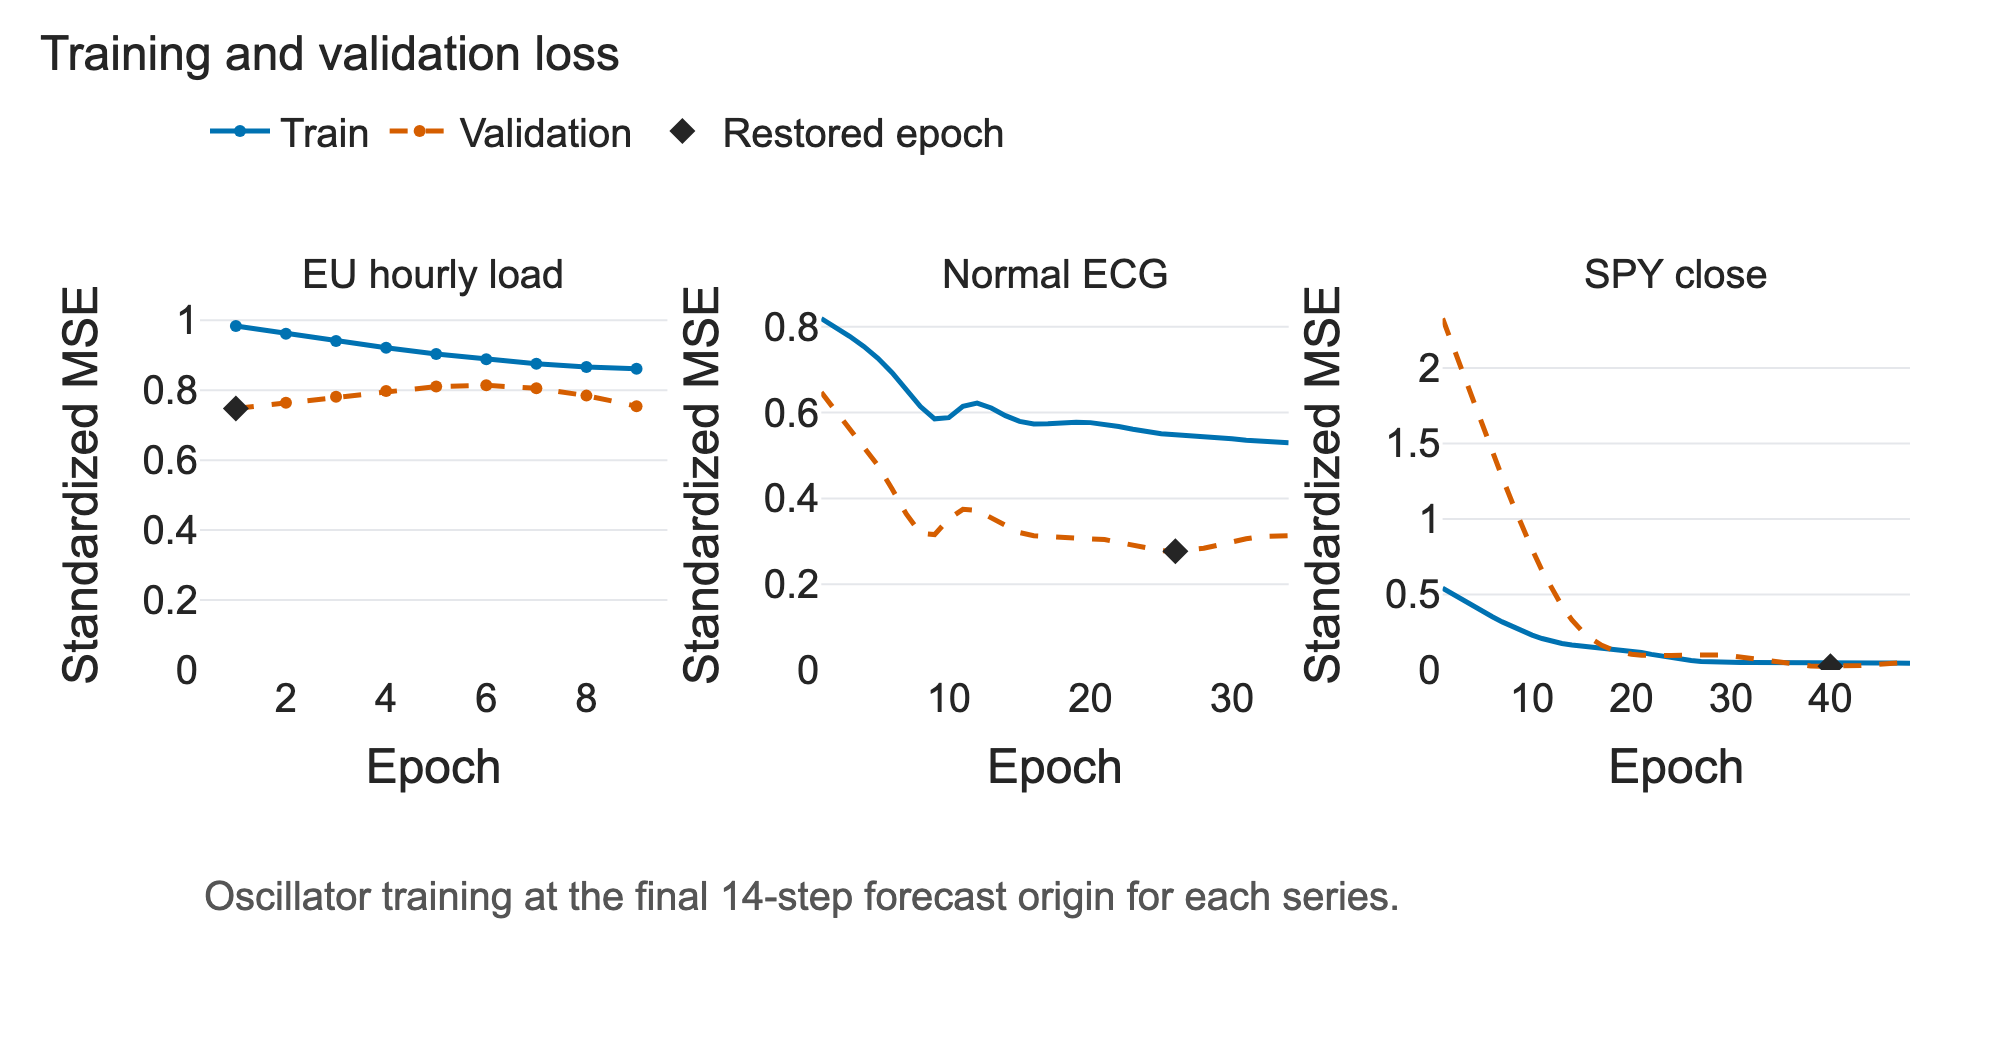

In [9]:
history = training_history
fig = make_subplots(rows=1, cols=3, subplot_titles=list(LABELS.values()), horizontal_spacing=0.09)
for column, key in enumerate(LABELS, 1):
    group = history[(history.series == key) & (history.horizon == 14) & (history.split == 10)]
    for metric, label, color, dash in [("train_mse", "Train", "#0072B2", "solid"), ("validation_mse", "Validation", "#D55E00", "dash")]:
        fig.add_trace(go.Scatter(x=group.epoch, y=group[metric], name=label, legendgroup=label, showlegend=column == 1,
                                line=dict(color=color, dash=dash, width=2.5)), row=1, col=column)
    best = group.loc[group.validation_mse.idxmin()]
    fig.add_trace(go.Scatter(x=[best.epoch], y=[best.validation_mse], name="Restored epoch", legendgroup="Best", showlegend=column == 1,
                            mode="markers", marker=dict(color="#252525", symbol="diamond", size=10)), row=1, col=column)
    fig.update_xaxes(title_text="Epoch", row=1, col=column)
    fig.update_yaxes(title_text="Standardized MSE", rangemode="tozero", row=1, col=column)
fig.update_layout(title="Training and validation loss")
show_figure(fig, "Oscillator training at the final 14-step forecast origin for each series.", height=520)

The curves separate optimization from forecast performance: a lower one-step training loss does not ensure that a fourteen-step recursive path remains accurate. The internal validation score also fluctuates, so retaining the last epoch would change the evaluated model.

For the final load origin, validation selects the first epoch: training loss continues falling, but validation never improves enough to replace that checkpoint before patience expires. This explains the nearly constant load forecast and shows that the fixed training setup failed to learn the cycle there. ECG retains epoch 26 and SPY epoch 40; their later validation minima indicate more useful weight adaptation, though the recursive forecasts still retain bias.

The oscillator has **561 trainable parameters**, compared with 1,233 in the Lab 4 LSTM. Fitting time is reported below for this execution. Processing a complete ECG beat requires 140 recurrent updates, so it costs more despite the same parameter count. All timings below use the current execution and the same CPU thread setting. Runtime and epoch counts are summarized by medians across ten origins at each fixed horizon. Forecast time covers the complete recursive path.

## 6. Median runtime comparison

Medians are calculated separately for each series, horizon and model. Whiskers span the 25th–75th percentiles across ten chronological origins; they describe variation between origins, not confidence intervals.

In [10]:
timing = comparison.groupby(["series", "horizon", "model"], as_index=False).agg(
    median_fit=("fit_seconds", "median"), median_forecast=("forecast_seconds", "median"),
    median_epochs=("epochs", "median")
)
for key, label in LABELS.items():
    table = timing[timing.series == key].copy()
    table["median_forecast"] *= 1000
    table["model"] = pd.Categorical(table.model, categories=models, ordered=True)
    table = table.sort_values(["horizon", "model"]).drop(columns="series").rename(columns={
        "horizon": "h", "model": "Model", "median_fit": "Median fit (s)",
        "median_forecast": "Median forecast (ms)", "median_epochs": "Median epochs"
    })
    show_table(table, f"{label}: medians across ten origins per horizon", decimals=4)


+--------------------------------------------------------------------------+
|          EU hourly load: medians across ten origins per horizon          |
+----+-------------+----------------+----------------------+---------------+
| h  | Model       | Median fit (s) | Median forecast (ms) | Median epochs |
+----+-------------+----------------+----------------------+---------------+
| 1  | ReLU MLP    | 0.0124         | 0.0367               | 39.5000       |
| 1  | Sigmoid MLP | 0.0152         | 0.0375               | 46.0000       |
| 1  | LSTM        | 0.5620         | 0.2945               | 73.0000       |
| 1  | Oscillator  | 0.1963         | 0.6571               | 34.0000       |
| 7  | ReLU MLP    | 0.0095         | 0.1310               | 28.0000       |
| 7  | Sigmoid MLP | 0.0107         | 0.1271               | 31.5000       |
| 7  | LSTM        | 0.6280         | 1.9211               | 80.0000       |
| 7  | Oscillator  | 0.1196         | 4.5802               | 19.0000       |

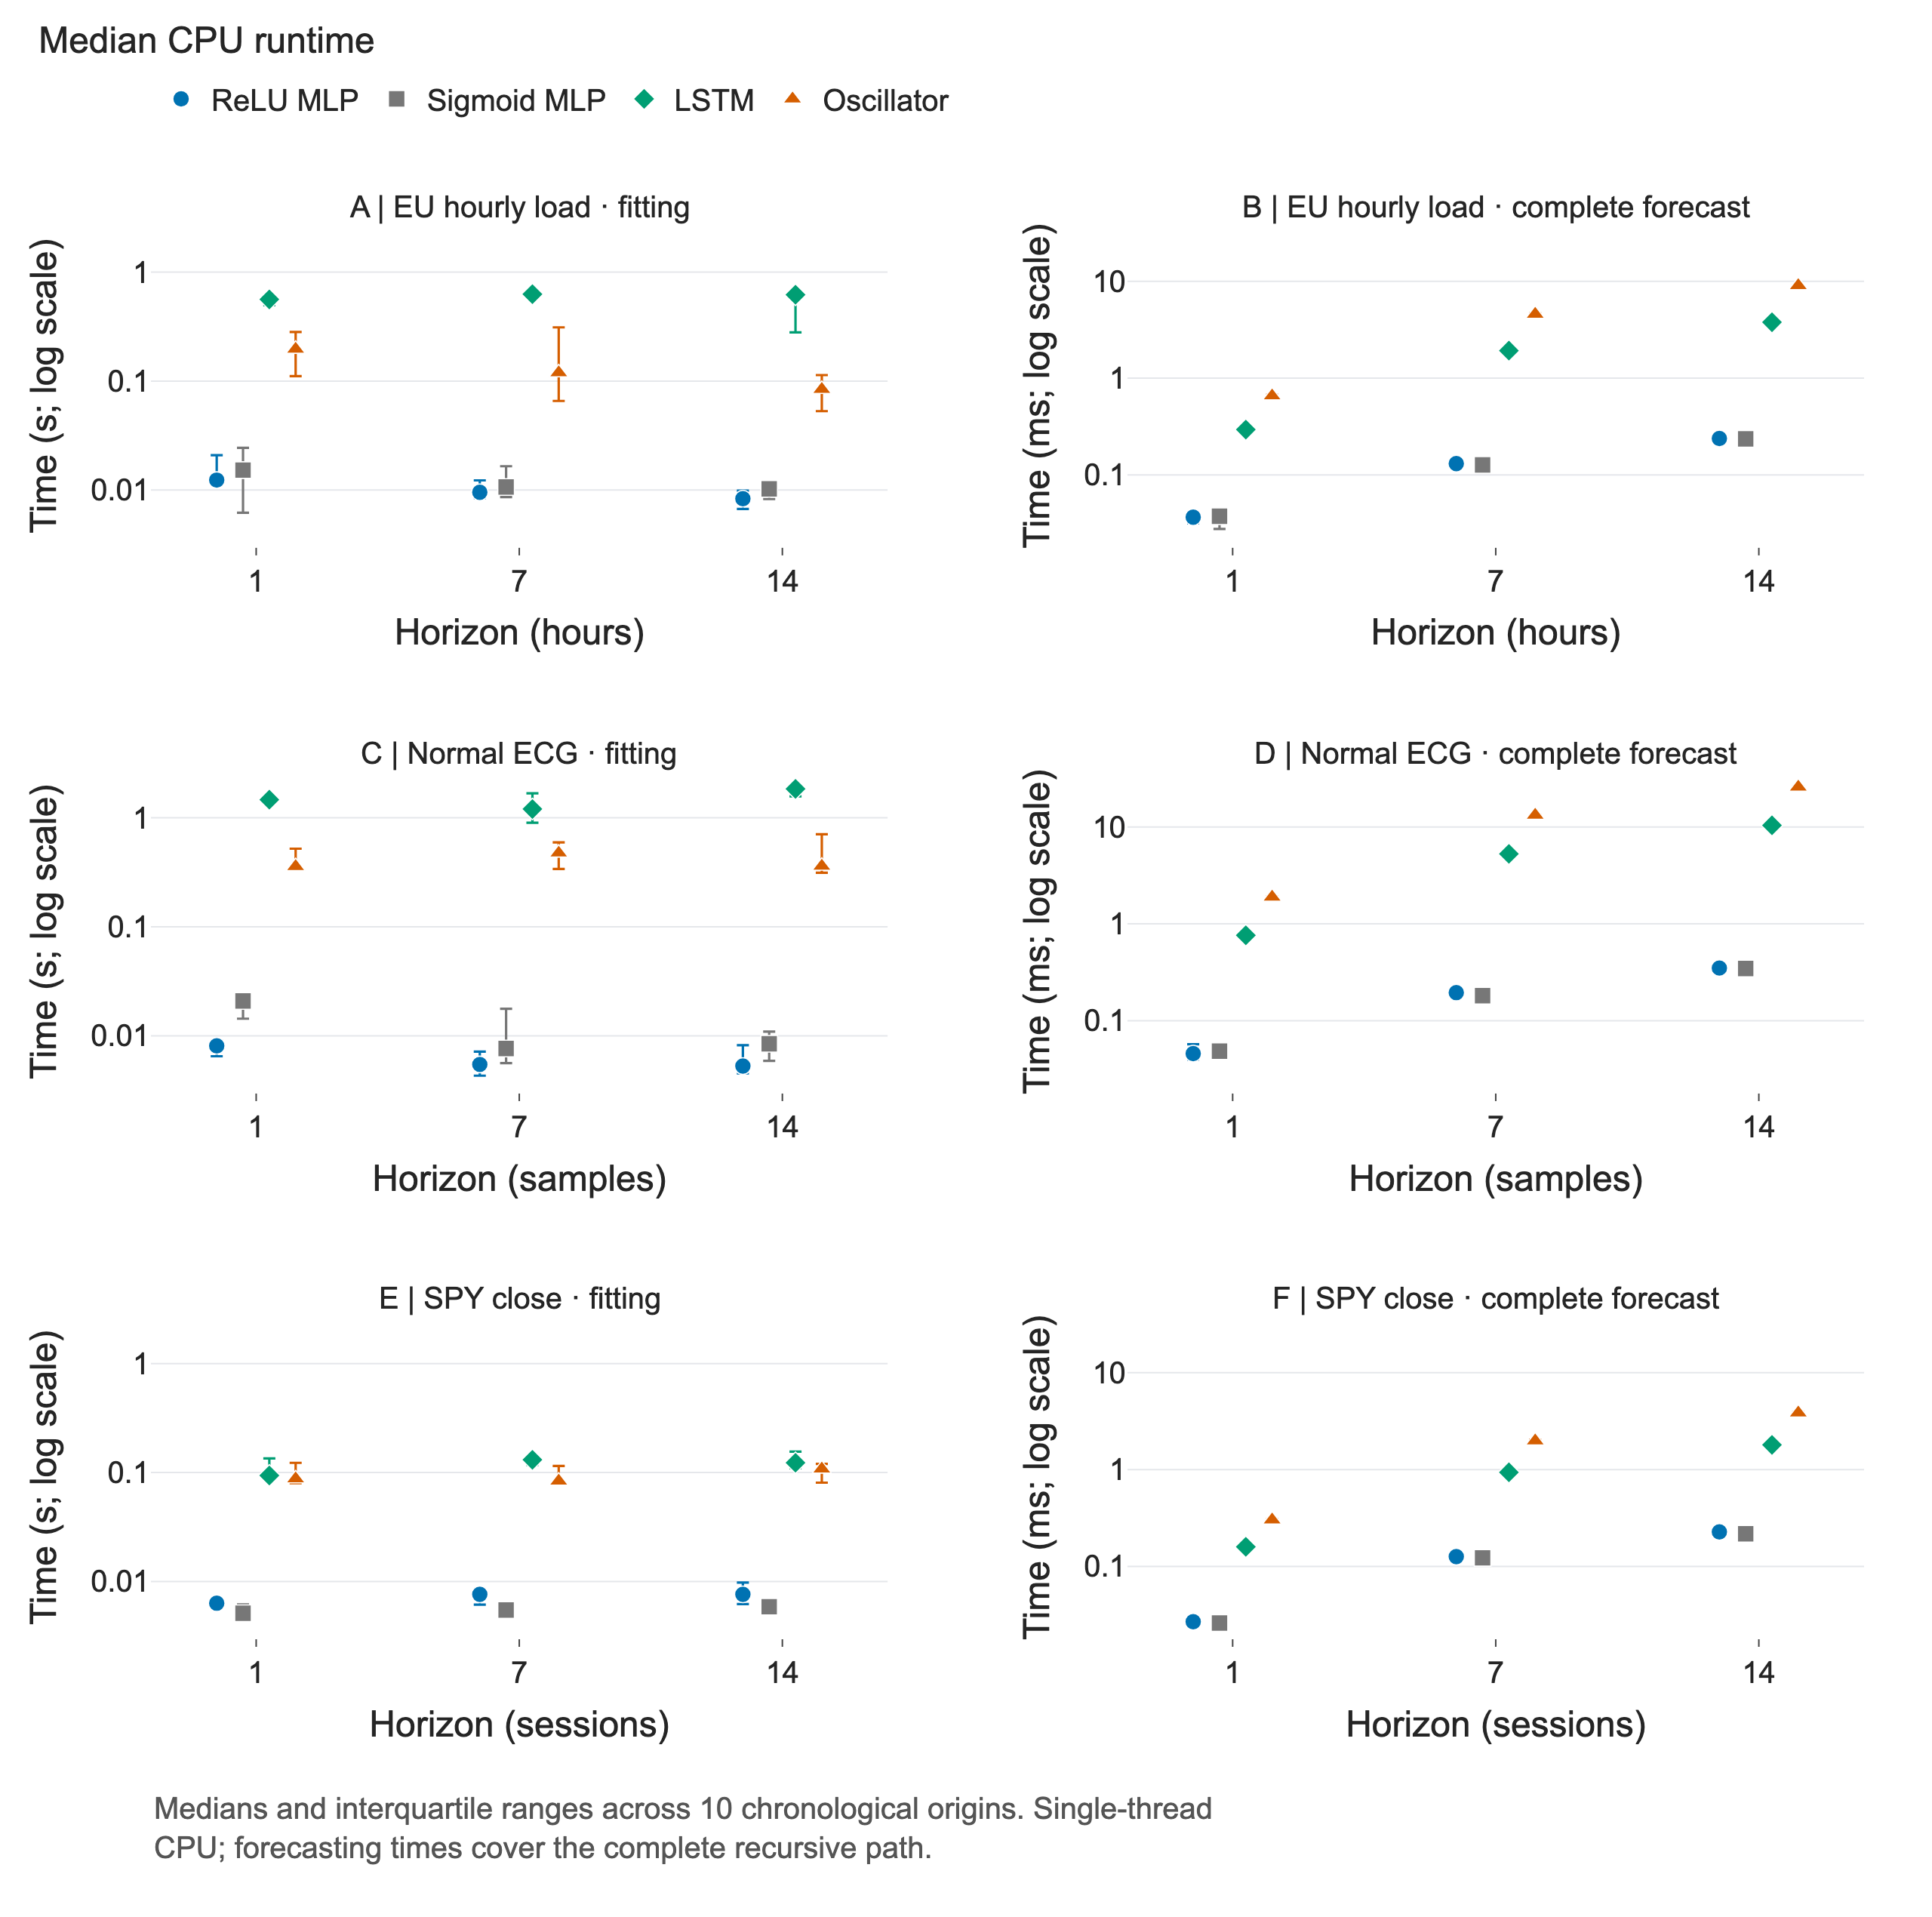

In [11]:
symbols = {"ReLU MLP": "circle", "Sigmoid MLP": "square", "LSTM": "diamond", "Oscillator": "triangle-up"}
stages = [("fit_seconds", 1, "Fitting", "s"), ("forecast_seconds", 1000, "Complete forecast", "ms")]
horizon_units = {"EU_Hourly_Load": "hours", "ECG_TF_Normal": "samples", "SPY_AdjClose": "sessions"}
fig = make_subplots(
    rows=3, cols=2, horizontal_spacing=0.14, vertical_spacing=0.16,
    subplot_titles=[
        f"{chr(65 + 2 * row + column)} | {label} · {stage.lower()}"
        for row, label in enumerate(LABELS.values())
        for column, (_, _, stage, _) in enumerate(stages)
    ],
)
for column, (metric, factor, _, unit) in enumerate(stages, 1):
    spread = comparison.groupby(["series", "horizon", "model"])[metric].agg(
        median="median", q1=lambda values: values.quantile(0.25), q3=lambda values: values.quantile(0.75)
    ).reset_index()
    limits = [np.log10(spread.q1.min() * factor) - 0.15, np.log10(spread.q3.max() * factor) + 0.15]
    ticks = 10.0 ** np.arange(np.ceil(limits[0]), np.floor(limits[1]) + 1)
    for row, key in enumerate(LABELS, 1):
        for offset, model in zip(np.linspace(-0.15, 0.15, len(models)), models):
            group = spread[(spread.series == key) & (spread.model == model)].sort_values("horizon")
            fig.add_trace(go.Scatter(
                x=np.arange(3) + offset, y=group["median"] * factor,
                name=model, legendgroup=model, showlegend=row == 1 and column == 1, mode="markers",
                marker=dict(size=11, symbol=symbols[model], color=COLORS[model],
                            line=dict(color="white", width=0.8)),
                error_y=dict(
                    type="data", symmetric=False, color=COLORS[model],
                    array=(group.q3 - group["median"]) * factor,
                    arrayminus=(group["median"] - group.q1) * factor,
                    thickness=1.6, width=4,
                ),
            ), row=row, col=column)
        fig.update_xaxes(
            title_text=f"Horizon ({horizon_units[key]})", tickvals=[0, 1, 2], ticktext=["1", "7", "14"],
            range=[-0.4, 2.4], ticks="outside", row=row, col=column,
        )
        fig.update_yaxes(
            title_text=f"Time ({unit}; log scale)", type="log", range=limits,
            tickvals=ticks, ticktext=[f"{value:g}" for value in ticks], row=row, col=column,
        )
fig.update_layout(title="Median CPU runtime", showlegend=True)
show_figure(
    fig, "Medians and interquartile ranges across 10 chronological origins. Single-thread CPU; forecasting times cover the complete recursive path.",
    height=1270, width=1280,
)


The dense networks have the lowest fitting cost. The oscillator often finishes training sooner than LSTM, partly because it stops after fewer epochs; fitting time alone does not isolate the computational cost of one epoch. The whiskers show that some origins need substantially more training than others.

During forecasting, the oscillator is slower than LSTM despite its smaller parameter count. Its Python recurrence visits every sample in the input window for each predicted step. Longer recursive horizons repeat that work, and the 140-sample ECG context is the most expensive. These are complete forecast-path times, not per-step latency.

## 7. Applicability and conclusion

The implemented oscillator is a valid recurrent forecasting model, but its fixed 16-unit configuration does not improve on ReLU MLP on any of the nine tasks by mean MAE. It is competitive with the LSTM in some settings, especially the persistent SPY level, without establishing a general advantage.

For load, the main challenge is preserving the cycle while adapting its amplitude and phase. For ECG, a smooth damped state can lose the sharp morphology, and the six-beat construction provides little independent training evidence. For SPY, following the latest level remains more useful than imposing oscillatory structure.

The comparison concerns these compact architectures, windows and stopping rules. Different damping, integration steps or training histories could change the outcome, but tuning them on these test blocks would invalidate the comparison. A separate earlier development segment and additional continuous ECG recordings would be the next useful experiments.